# GeoFWI | Differentiable Post-stack Acoustic Impedance Inversion

**A complete benchmark using an authentic 10-layer GeoFWI model with PyTorch automatic differentiation**

This tutorial demonstrates: geological model selection → density and impedance → exact normal-incidence reflectivity → wavelet convolution → noisy post-stack data → band-limited inversion → regularized AD inversion → quantitative evaluation.

**Physics and limitations.** This is a zero-offset, normal-incidence, 1D convolutional post-stack approximation (one forward model per trace), *not* full-waveform inversion. Impedance is not uniquely recoverable from band-limited seismic without low-frequency information. The background impedance supplied to inversion is a synthetic proxy for independent well/low-frequency constraints; it is not the true impedance. The model and data use a fixed depth-to-time conversion for instructional clarity, so there is no time-depth inversion.

**Source:** [GeoFWI repository](https://github.com/aaspip/geofwi); Li et al. (2026), DOI: 10.1029/2025JH001037. If local GeoFWI data are unavailable, the notebook generates a reproducible **GeoFWI-inspired** 10-layer folded model, explicitly identified as synthetic fallback.

**Requirements:** `pip install numpy scipy matplotlib torch geofwi` (GeoFWI dataset files are optional). Runs on CPU or CUDA/MPS when supported. No external download is performed.

In [1]:
from pathlib import Path
import copy, random, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.ndimage import gaussian_filter
from scipy.signal import butter, sosfiltfilt
import torch
import torch.nn.functional as F

SEED=2026
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
DT=0.004  # seconds/sample; illustrative time sampling
DX=12.5  # meters/trace; illustrative spatial sampling
NX=NZ=100
SNR_DB=18.0
OUT=Path('geofwi_poststack_results'); OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':120,'savefig.dpi':180,'font.size':10,'axes.titlesize':11,'axes.labelsize':10,'image.interpolation':'nearest'})
print('Torch',torch.__version__,'device',DEVICE,'output',OUT.resolve())

Torch 2.10.0 device mps output /Users/chenyk/aaspip.geofwi/notebooks/geofwi_poststack_results


## 1. Download and select a genuine 10-layer GeoFWI model

The official `geofwi.download(progress=True)` downloads, verifies, and extracts the GeoFWI archive into its platform-specific dataset directory. The selection below follows the repository README's ordered category metadata: categories 24, 25, and 26 correspond to 10-layer fold, fault, and salt models, respectively (zero-based indexing). `INDEX` selects a model within the category. **No generated or substitute velocity model is permitted**; missing files cause a clear error. The data may be large, so download once and reuse the verified local copy.

GeoFWI source: https://github.com/aaspip/geofwi  ·  Dataset: https://zenodo.org/records/24061019


Already downloaded and verified: /Users/chenyk/Datasets/GeoFWI/geofwi.zip
Downloaded/extracted GeoFWI directory: /Users/chenyk/Datasets/GeoFWI/geofwi
Source: GeoFWI 10-layer fold, local index 0, global index 43425 | shape=(100, 100) | Vp=1558–3961 m/s
Velocity file: /Users/chenyk/Datasets/GeoFWI/geofwi/geofwi/geofwi.npy


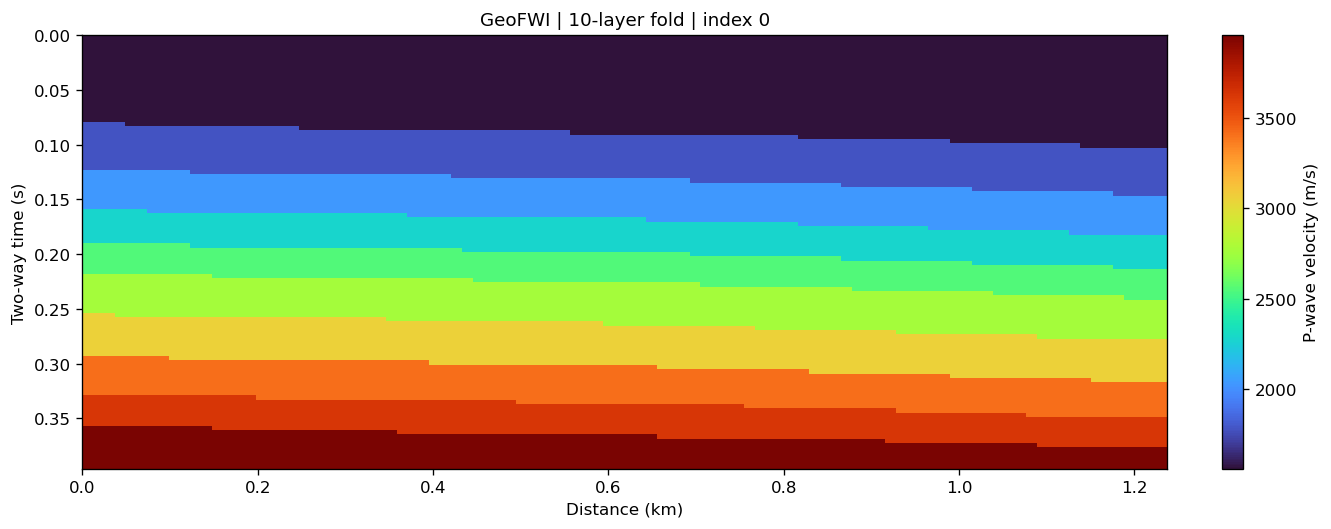

In [2]:
import geofwi

MODE = "fold"                 # Choose "fold", "fault", or "salt"
INDEX = 0                     # Zero-based index within the chosen category

# Official GeoFWI downloader: checksum verification, progress bar, extraction.
# Requires a current geofwi installation with download() exposed.
if not callable(getattr(geofwi, "download", None)):
    raise ImportError("Install/update GeoFWI: pip install -U git+https://github.com/aaspip/geofwi")
DATA_PATH = Path(geofwi.download(progress=True)).expanduser().resolve()
print("Downloaded/extracted GeoFWI directory:", DATA_PATH)

# Find the two official NumPy files, including nested extraction directories.
def find_unique_file(root, filename):
    matches = sorted(root.rglob(filename))
    if not matches:
        raise FileNotFoundError(
            f"Required official GeoFWI file {filename!r} not found under {root}. "
            "Verify the downloaded archive and its extracted contents."
        )
    if len(matches) > 1:
        raise RuntimeError(f"Ambiguous GeoFWI files named {filename}: {matches}")
    return matches[0]

velocity_file = find_unique_file(DATA_PATH, "geofwi.npy")
metadata_file = find_unique_file(DATA_PATH, "geofwi-size-layer-fault-salt-1-10.npy")
sizes = np.load(metadata_file)
if sizes.ndim != 1 or len(sizes) < 27:
    raise ValueError(f"Unexpected GeoFWI category metadata shape: {sizes.shape}")
if MODE not in {"fold", "fault", "salt"}:
    raise ValueError("MODE must be one of: fold, fault, salt")
category = 24 + {"fold": 0, "fault": 1, "salt": 2}[MODE]
category_count = int(sizes[category])
if not (0 <= INDEX < category_count):
    raise IndexError(f"INDEX={INDEX} out of range for 10-layer {MODE} (0..{category_count-1})")
global_index = int(np.sum(sizes[:category], dtype=np.int64)) + INDEX

# Memory-map the large dataset: only the selected model is read into RAM.
dataset = np.load(velocity_file, mmap_mode="r")
if dataset.ndim != 3 or global_index >= dataset.shape[0]:
    raise ValueError(f"Unexpected dataset shape/index: {dataset.shape}, index={global_index}")
vp = np.array(dataset[global_index], dtype=np.float32, copy=True)
if vp.ndim != 2 or not np.all(np.isfinite(vp)) or np.min(vp) <= 0:
    raise ValueError("Selected GeoFWI velocity model is invalid")
source = f"GeoFWI 10-layer {MODE}, local index {INDEX}, global index {global_index}"
NZ, NX = vp.shape
x = np.arange(NX) * DX / 1000
t = np.arange(NZ) * DT
print(f"Source: {source} | shape={vp.shape} | Vp={vp.min():.0f}–{vp.max():.0f} m/s")
print("Velocity file:", velocity_file)

fig, ax = plt.subplots(figsize=(11, 4.3), constrained_layout=True)
im = ax.imshow(vp, extent=[x[0], x[-1], t[-1], t[0]], aspect="auto", cmap="turbo")
ax.set(title=f"GeoFWI | 10-layer {MODE} | index {INDEX}",
       xlabel="Distance (km)", ylabel="Two-way time (s)")
fig.colorbar(im, ax=ax, label="P-wave velocity (m/s)")
fig.savefig(OUT / "01_velocity.png")
plt.show()


## 2. Density, acoustic impedance, and reflection coefficients

For this synthetic **post-stack seismic experiment based on an actual GeoFWI velocity model**, density follows an illustrative Gardner-style relationship, $\rho=310V_p^{0.25}$ with $V_p$ in m/s and $\rho$ in kg/m³. This creates a correlated density field; density is **not independently measured**. Normal-incidence reflectivity is calculated exactly from neighboring impedance samples. Inversion estimates impedance, not separate velocity and density.

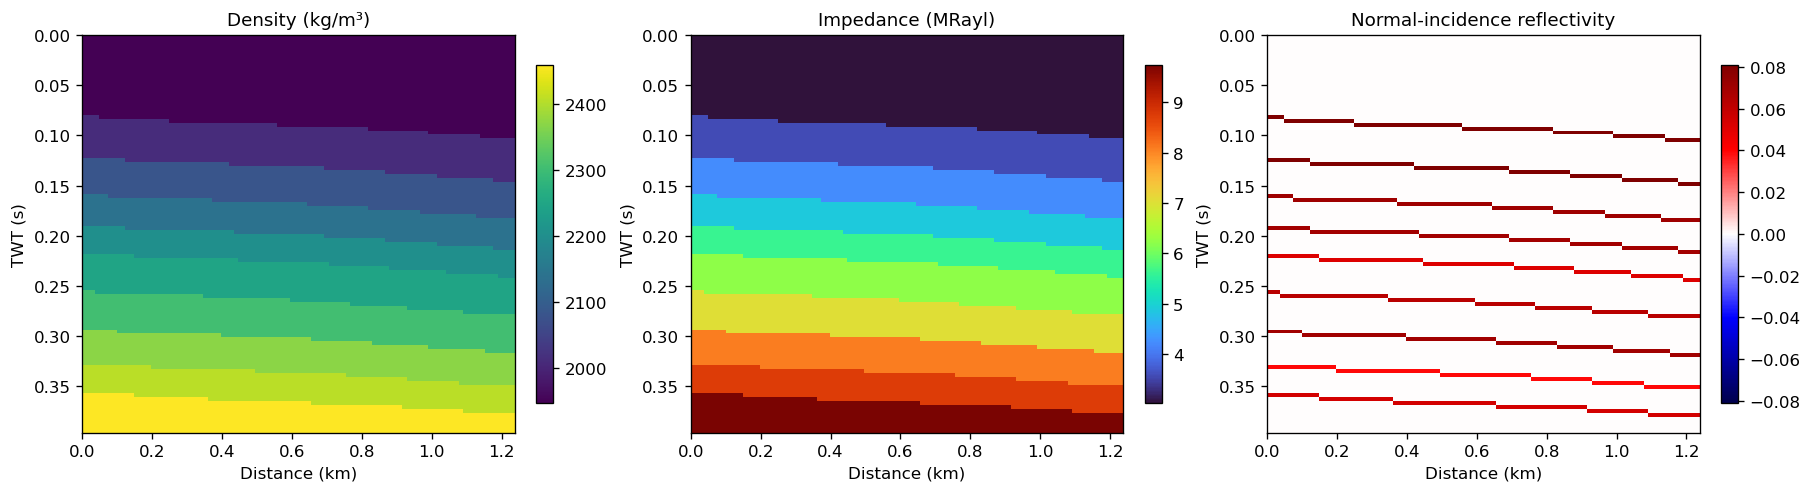

In [3]:
rho=310.0*np.power(vp,0.25)
Z_true=(rho*vp).astype('float32')
logZ_true=np.log(Z_true)
R_true=np.zeros_like(Z_true)
R_true[1:]=(Z_true[1:]-Z_true[:-1])/(Z_true[1:]+Z_true[:-1])
fig,axs=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for a,A,title,cmap in zip(axs,[rho,Z_true/1e6,R_true],['Density','Acoustic impedance','Normal-incidence reflectivity'],['viridis','turbo','seismic']):
    lim=max(abs(np.percentile(A,1)),abs(np.percentile(A,99))) if cmap=='seismic' else None
    im=a.imshow(A,extent=[x[0],x[-1],t[-1],t[0]],aspect='auto',cmap=cmap,vmin=-lim if lim else None,vmax=lim if lim else None)
    a.set(title=title,xlabel='Distance (km)',ylabel='TWT (s)');fig.colorbar(im,ax=a,shrink=.85)
axs[0].set_title('Density (kg/m³)');axs[1].set_title('Impedance (MRayl)')
fig.savefig(OUT/'02_rock_properties.png');plt.show()

## 3. Forward modeling: Ricker wavelet, reflectivity convolution, noise

The differentiable forward operator is $d = W r(\log Z)$, where $r_i=\tanh[(\log Z_i-\log Z_{i-1})/2]$. This is exactly equivalent to the impedance-ratio formula. A same-length 1D convolution is applied along the vertical/time axis of every trace. A zero-phase Ricker wavelet is used; additive Gaussian noise is calibrated to a target global RMS SNR.

Actual SNR: 18.0 dB


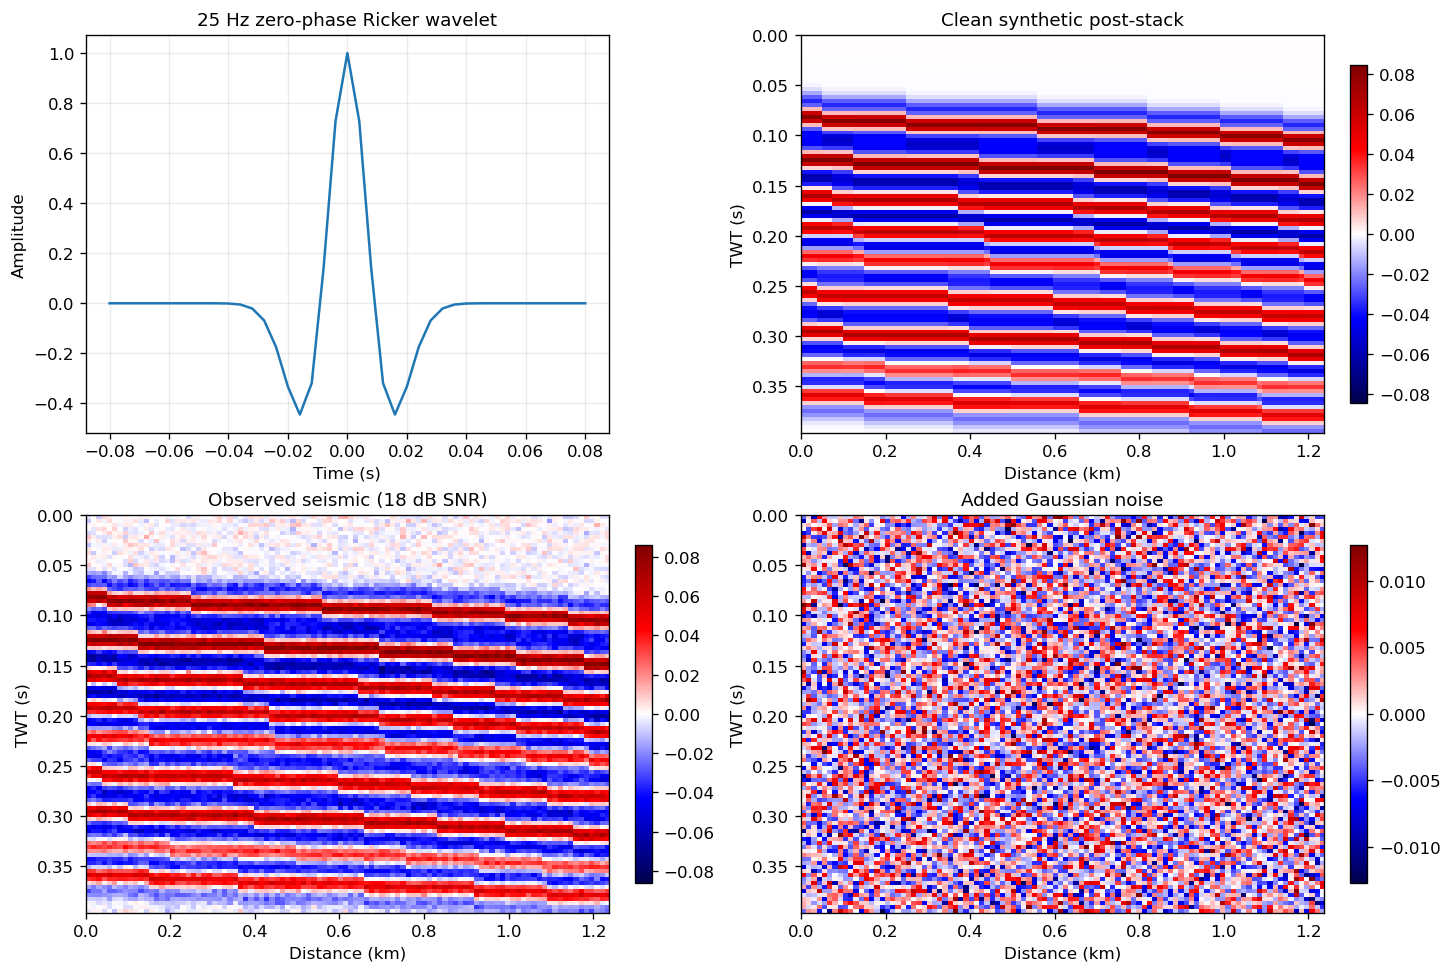

In [4]:
def ricker(freq,dt,halfwidth=0.08):
    tt=np.arange(-round(halfwidth/dt),round(halfwidth/dt)+1)*dt
    a=(np.pi*freq*tt)**2
    return tt,((1-2*a)*np.exp(-a)).astype('float32')

def torch_forward(logz,wavelet):
    # logz [nz,nx], wavelet [odd length]; convolution is per lateral trace
    r=torch.tanh(0.5*(logz[1:]-logz[:-1]))
    r=F.pad(r.T.unsqueeze(1),(1,0))  # [nx,1,nz], zero at top
    y=F.conv1d(r,wavelet.flip(0).reshape(1,1,-1),padding=wavelet.numel()//2)
    return y[:,0,:].T

freq=25.0
wt,w_np=ricker(freq,DT)
w=torch.tensor(w_np,device=DEVICE)
true_tensor=torch.tensor(logZ_true,device=DEVICE)
with torch.no_grad(): clean=torch_forward(true_tensor,w).cpu().numpy()
rng=np.random.default_rng(SEED)
noise=rng.normal(size=clean.shape).astype('float32')
noise*=np.sqrt(np.mean(clean**2))/np.sqrt(np.mean(noise**2))/10**(SNR_DB/20)
observed=clean+noise
print('Actual SNR:',20*np.log10(np.linalg.norm(clean)/np.linalg.norm(noise)),'dB')
fig,axs=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
axs[0,0].plot(wt,w_np);axs[0,0].set(title=f'{freq:g} Hz zero-phase Ricker wavelet',xlabel='Time (s)',ylabel='Amplitude');axs[0,0].grid(alpha=.25)
for a,A,ttl in [(axs[0,1],clean,'Clean synthetic post-stack'),(axs[1,0],observed,f'Observed seismic ({SNR_DB:g} dB SNR)'),(axs[1,1],noise,'Added Gaussian noise')]:
    lim=np.percentile(abs(A),99.5);im=a.imshow(A,extent=[x[0],x[-1],t[-1],t[0]],aspect='auto',cmap='seismic',vmin=-lim,vmax=lim)
    a.set(title=ttl,xlabel='Distance (km)',ylabel='TWT (s)');fig.colorbar(im,ax=a,shrink=.85)
fig.savefig(OUT/'03_forward_model.png');plt.show()

## 4. Low-frequency model and inversion objective

The wavelet suppresses zero frequency, so absolute impedance is non-identifiable from post-stack traces alone. We construct a **deliberately imperfect** background by strong Gaussian smoothing and a smooth lateral/depth bias. This background represents external low-frequency constraints, not information inferred from seismic data.

Optimize $m=\log Z$ with

$$\mathcal L(m)=\frac{\|W r(m)-d\|_2^2}{\mathrm{RMS}(d)^2 N}+\lambda_b\frac{\|G_\sigma(m-m_b)\|_2^2}{s_m^2 N}+\lambda_{TV}\operatorname{TV}_\epsilon(m).$$

In implementation, the background term penalizes a **Gaussian-smoothed residual** relative to $m_b$ (not every high-frequency correction). The TV term is differentiable Charbonnier TV, promoting piecewise-smooth geology. The Gaussian smoother is fixed, differentiable and separable. The regularization coefficients below are instructional hyperparameters, not tuned on independent test data.

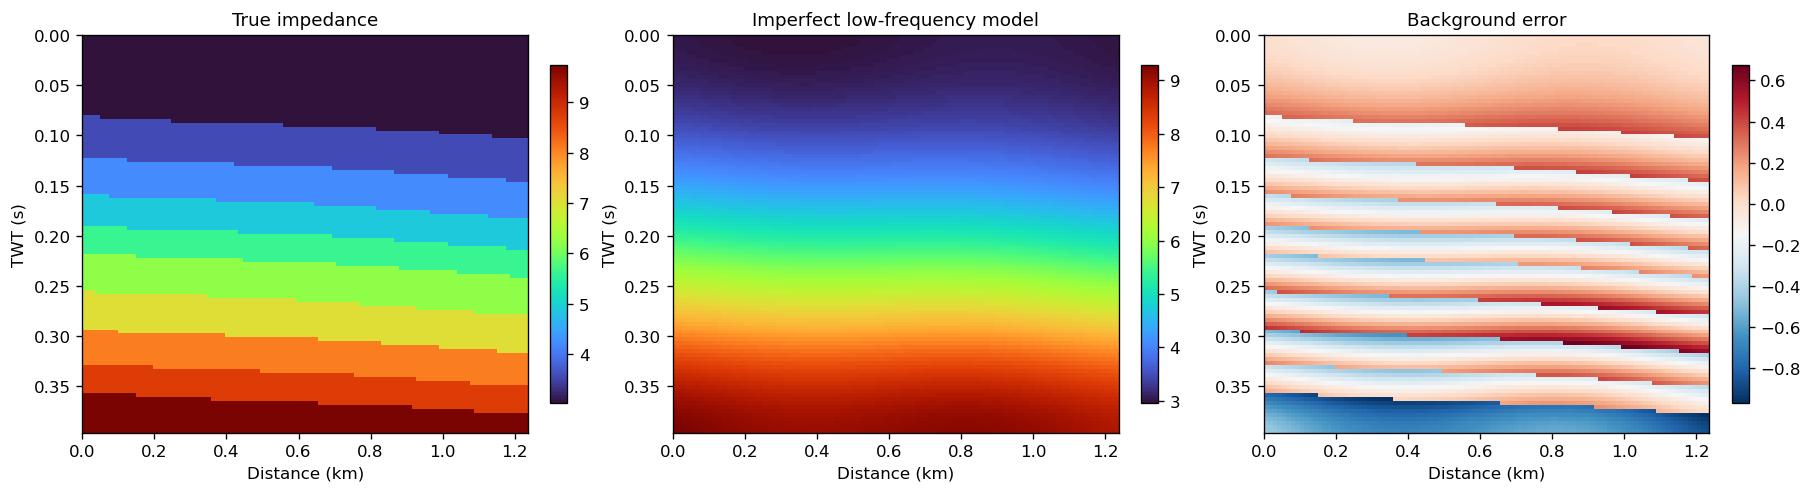

In [5]:
# Background model: strongly smoothed true model + smooth, nontrivial bias.
# In real applications obtain this from wells, horizons, velocity/density trends or other independent information.
mb=gaussian_filter(logZ_true,sigma=(13,11))
zz=np.linspace(-1,1,NZ)[:,None];xx=np.linspace(-1,1,NX)[None,:]
mb=mb+(0.025*zz+0.018*np.sin(np.pi*xx))*np.ones((NZ,1))
mb=mb.astype('float32')

def gauss_kernel(sigma,device):
    radius=max(1,int(np.ceil(3*sigma)));u=torch.arange(-radius,radius+1,device=device,dtype=torch.float32)
    k=torch.exp(-0.5*(u/sigma)**2);return k/k.sum()

def blur2d(a,sigma=7.0):
    k=gauss_kernel(sigma,a.device);pad=k.numel()//2
    y=F.conv2d(F.pad(a[None,None],(pad,pad,0,0),mode='replicate'),k.view(1,1,1,-1))
    y=F.conv2d(F.pad(y,(0,0,pad,pad),mode='replicate'),k.view(1,1,-1,1))
    return y[0,0]

fig,axs=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for a,A,title in zip(axs,[Z_true/1e6,np.exp(mb)/1e6,(np.exp(mb)-Z_true)/1e6],['True impedance','Imperfect low-frequency model','Background error']):
    im=a.imshow(A,extent=[x[0],x[-1],t[-1],t[0]],aspect='auto',cmap='RdBu_r' if 'error' in title.lower() else 'turbo')
    a.set(title=title,xlabel='Distance (km)',ylabel='TWT (s)');fig.colorbar(im,ax=a,shrink=.85)
fig.savefig(OUT/'04_background.png');plt.show()

## 5. Reliable AD gradient verification (double precision)

The forward model and inversion may run in single precision, but numerical differentiation of a scalar loss can suffer cancellation when a unit-normalized perturbation is spread across thousands of pixels. We therefore check the **same discrete reflectivity/convolution operator** on CPU in `float64`, with a gradient-aligned unit direction and a sweep of step sizes. This tests the analytical AD gradient against central differences without relying on a single arbitrary finite-difference step. The inversion itself still uses the configured `DEVICE` and `float32`.


In [6]:
obs=torch.tensor(observed,device=DEVICE)
base=torch.tensor(mb,device=DEVICE)
scale=obs.square().mean().detach().clamp_min(1e-10)
def data_loss(m,wavelet=w):
    return (torch_forward(m,wavelet)-obs).square().mean()/scale

# Gradient check in float64 on CPU to avoid cancellation and MPS float64 limitations.
check_device=torch.device('cpu')
check_obs=torch.as_tensor(observed,dtype=torch.float64,device=check_device)
check_wavelet=torch.as_tensor(w_np,dtype=torch.float64,device=check_device)
check_base=torch.as_tensor(mb,dtype=torch.float64,device=check_device)
check_scale=check_obs.square().mean().clamp_min(1e-20)
def check_loss(m):
    return (torch_forward(m,check_wavelet)-check_obs).square().mean()/check_scale

m_check=check_base.clone().detach().requires_grad_(True)
check_grad=torch.autograd.grad(check_loss(m_check),m_check)[0]
grad_norm=check_grad.norm().item()
if not np.isfinite(grad_norm) or grad_norm <= 1e-14:
    raise RuntimeError('Gradient is zero or non-finite: inspect the forward model and observations.')

# The gradient-aligned direction gives a measurable, nonzero directional derivative.
direction=(check_grad/check_grad.norm()).detach()
ad=float((check_grad*direction).sum())
results=[]
with torch.no_grad():
    for eps in [1e-1,3e-2,1e-2,3e-3,1e-3]:
        fd=float((check_loss(m_check+eps*direction)-check_loss(m_check-eps*direction))/(2*eps))
        relative=abs(fd-ad)/max(abs(fd),abs(ad),1e-12)
        results.append((eps,fd,relative))
        print(f'eps={eps:.0e}  FD={fd:.9e}  AD={ad:.9e}  relative error={relative:.3e}')

best=min(results,key=lambda result:result[2])
print(f'Best step={best[0]:.0e}; relative discrepancy={best[2]:.3e}')
assert best[2] < 1e-4, 'Double-precision gradient check failed: inspect forward operator and objective.'
print('PASS: PyTorch AD agrees with central finite differences.')

eps=1e-01  FD=7.095006986e-01  AD=7.095007559e-01  relative error=8.084e-08
eps=3e-02  FD=7.095007507e-01  AD=7.095007559e-01  relative error=7.275e-09
eps=1e-02  FD=7.095007553e-01  AD=7.095007559e-01  relative error=8.084e-10
eps=3e-03  FD=7.095007559e-01  AD=7.095007559e-01  relative error=7.278e-11
eps=1e-03  FD=7.095007559e-01  AD=7.095007559e-01  relative error=8.471e-12
Best step=1e-03; relative discrepancy=8.471e-12
PASS: PyTorch AD agrees with central finite differences.


## 6. Multiscale regularized inversion with Adam and L-BFGS refinement

We optimize the entire 2D log-impedance field. The seismic term remains trace-local; lateral continuity comes from TV. A frequency-continuation schedule uses 12, 18, then 25 Hz wavelets, with synthetic observations regenerated from the **same noisy seismic** through an approximate band-limiting filter. To avoid an inconsistent source wavelet, instead we use the same recorded seismic and the original 25 Hz forward wavelet throughout, while gradually releasing regularization. This is a *regularization-continuation* strategy rather than claiming a physically exact frequency-continuation inversion.

Compare (a) data-only AD inversion and (b) low-frequency-constrained, TV-regularized AD inversion. Both start from the same imperfect background. A final L-BFGS polish refines the regularized result.

Optimization elapsed: 3.0 s


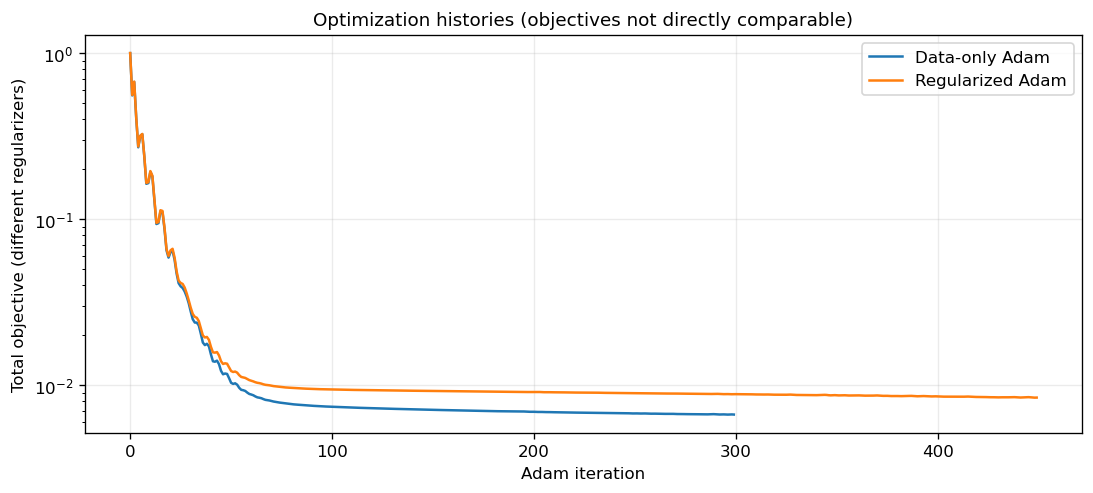

In [7]:
def objective(m,reg=True,lam_b=0.8,lam_tv=0.04):
    ld=data_loss(m)
    if not reg:return ld, (ld.detach(),torch.tensor(0.,device=DEVICE),torch.tensor(0.,device=DEVICE))
    # Penalize only low-spatial-frequency departure from independent background.
    low=blur2d(m-base,sigma=7)
    lb=(low.square().mean())/(0.10**2)
    dx=m[:,1:]-m[:,:-1];dz=m[1:]-m[:-1]
    tv=(torch.sqrt(dx.square()+1e-5).mean()+torch.sqrt(dz.square()+1e-5).mean())/2
    return ld+lam_b*lb+lam_tv*tv,(ld.detach(),lb.detach(),tv.detach())

def invert(reg=True,steps=360,lr=0.045):
    m=torch.nn.Parameter(base.clone());optimizer=torch.optim.Adam([m],lr=lr)
    history=[];best=float('inf');bestm=None
    for it in range(steps):
        optimizer.zero_grad()
        if reg:
            # Progressive release of smoothing/TV, retaining a low-frequency anchor
            frac=it/max(1,steps-1)
            lb=1.2-0.5*frac;tv=0.08-0.045*frac
        else:lb=tv=0
        loss,parts=objective(m,reg,lb,tv)
        loss.backward();torch.nn.utils.clip_grad_norm_([m],max_norm=10)
        optimizer.step()
        with torch.no_grad():m.clamp_(np.log(1e6),np.log(25e6))
        val=float(loss.detach());history.append([val,*[float(q) for q in parts]])
        if val<best:best=val;bestm=m.detach().clone()
    return bestm,np.asarray(history)

start=time.time()
m_unreg,h_unreg=invert(reg=False,steps=300)
m_reg,h_reg=invert(reg=True,steps=450)
# L-BFGS final refinement with fixed final objective (no truth information)
mparam=torch.nn.Parameter(m_reg.clone())
lbfgs=torch.optim.LBFGS([mparam],lr=0.55,max_iter=55,history_size=20,line_search_fn='strong_wolfe')
def closure():
    lbfgs.zero_grad();loss,_=objective(mparam,True,0.7,0.035);loss.backward();return loss
lbfgs.step(closure)
with torch.no_grad():mparam.clamp_(np.log(1e6),np.log(25e6))
m_reg=mparam.detach()
print('Optimization elapsed: %.1f s'%(time.time()-start))
fig,ax=plt.subplots(figsize=(9,4),constrained_layout=True)
ax.semilogy(h_unreg[:,0],label='Data-only Adam');ax.semilogy(h_reg[:,0],label='Regularized Adam')
ax.set(xlabel='Adam iteration',ylabel='Total objective (different regularizers)',title='Optimization histories (objectives not directly comparable)');ax.legend();ax.grid(alpha=.25)
fig.savefig(OUT/'05_optimization.png');plt.show()

## 7. Impedance and seismic reconstruction: maps, residuals, traces

Absolute impedance quality is evaluated against synthetic truth **only after inversion**. Seismic reconstruction is evaluated against noisy observations and separately against the noise-free synthetic data (the latter is an oracle diagnostic, not an operational metric).

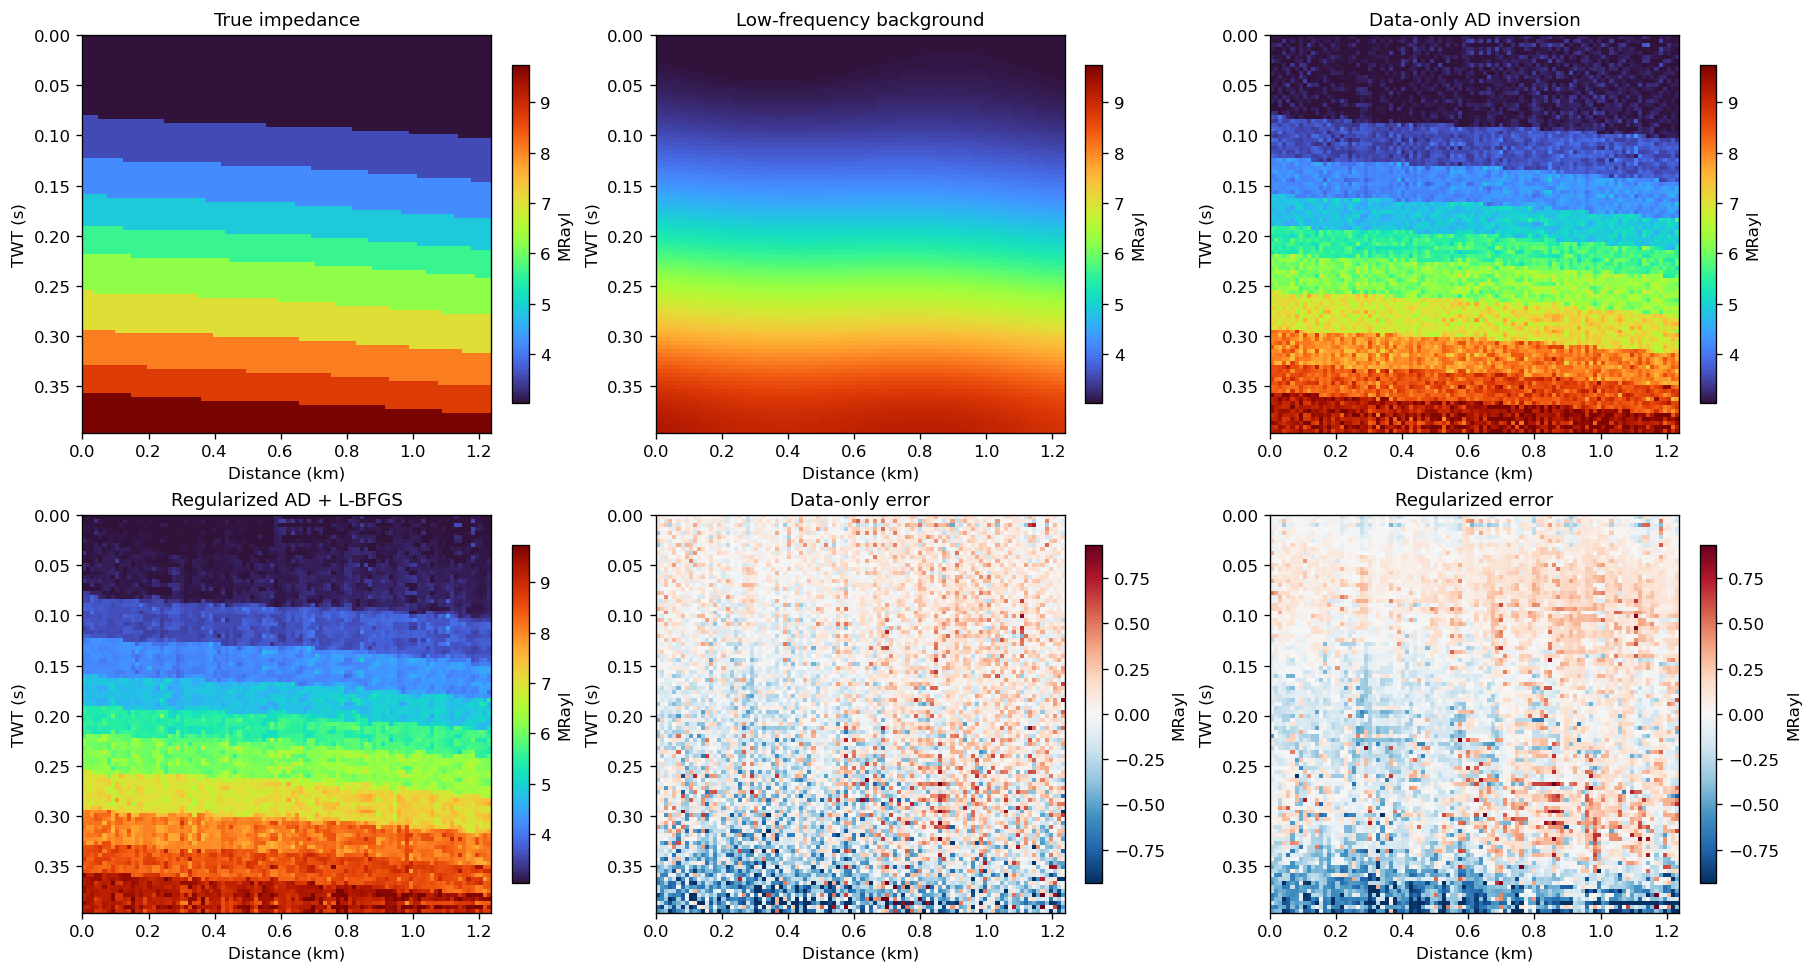

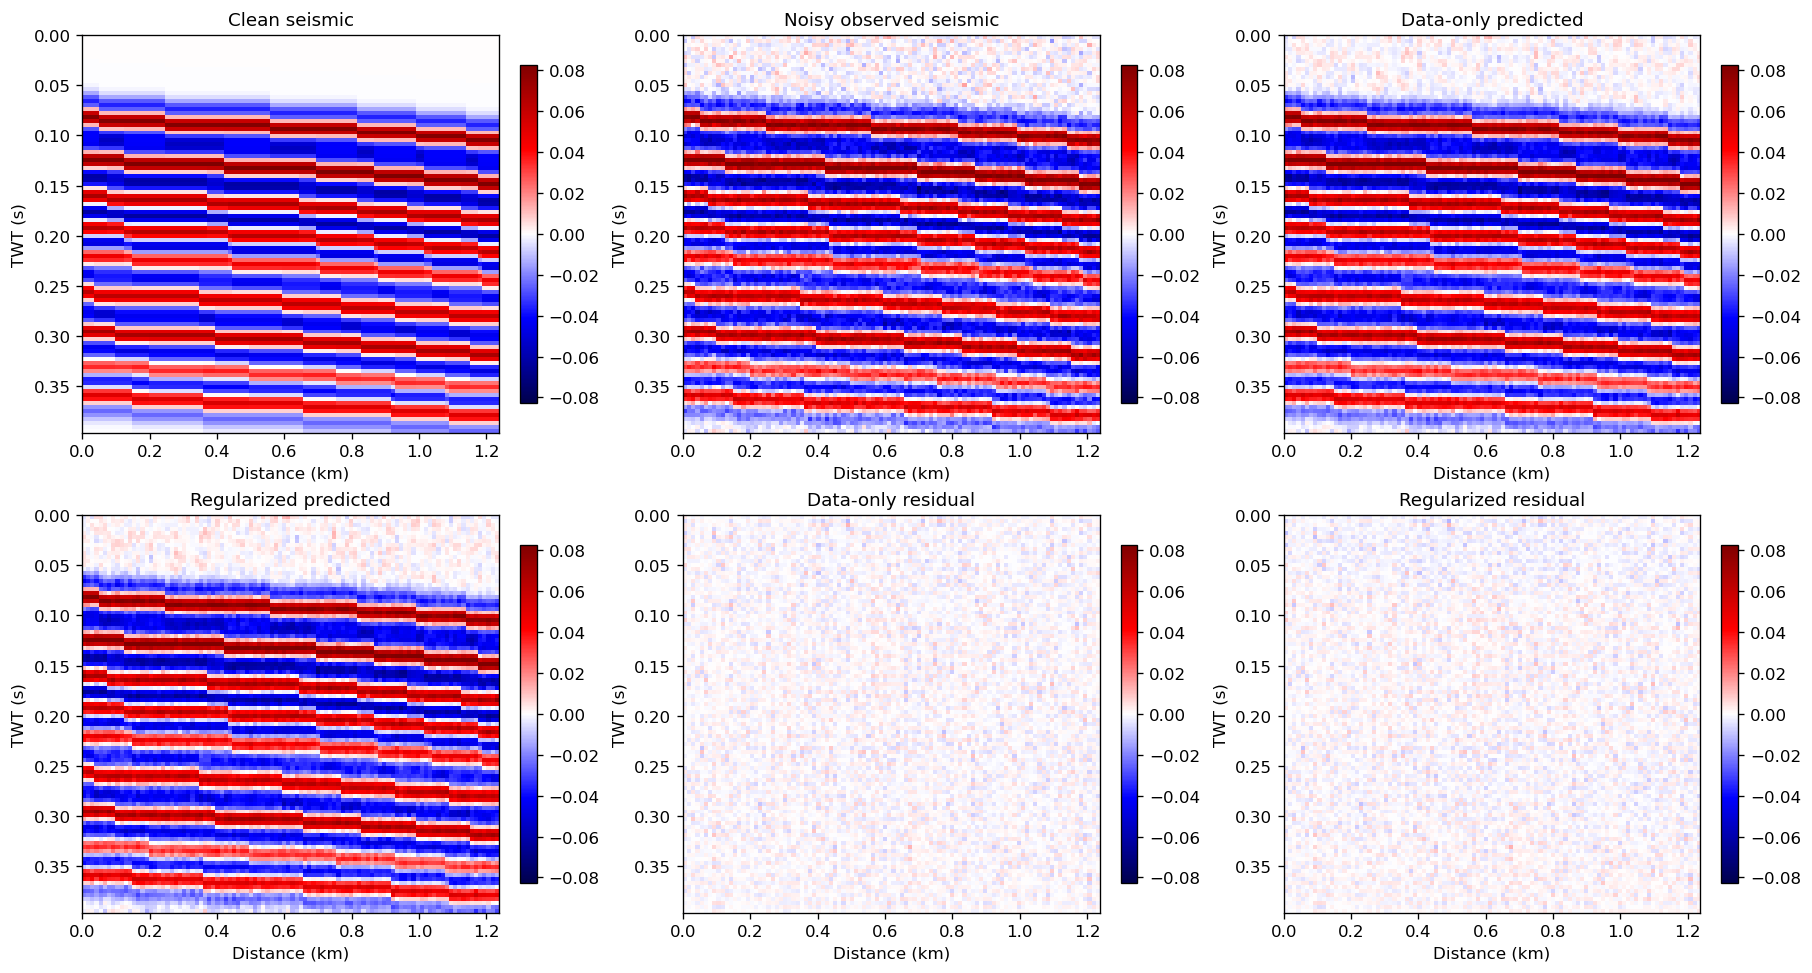

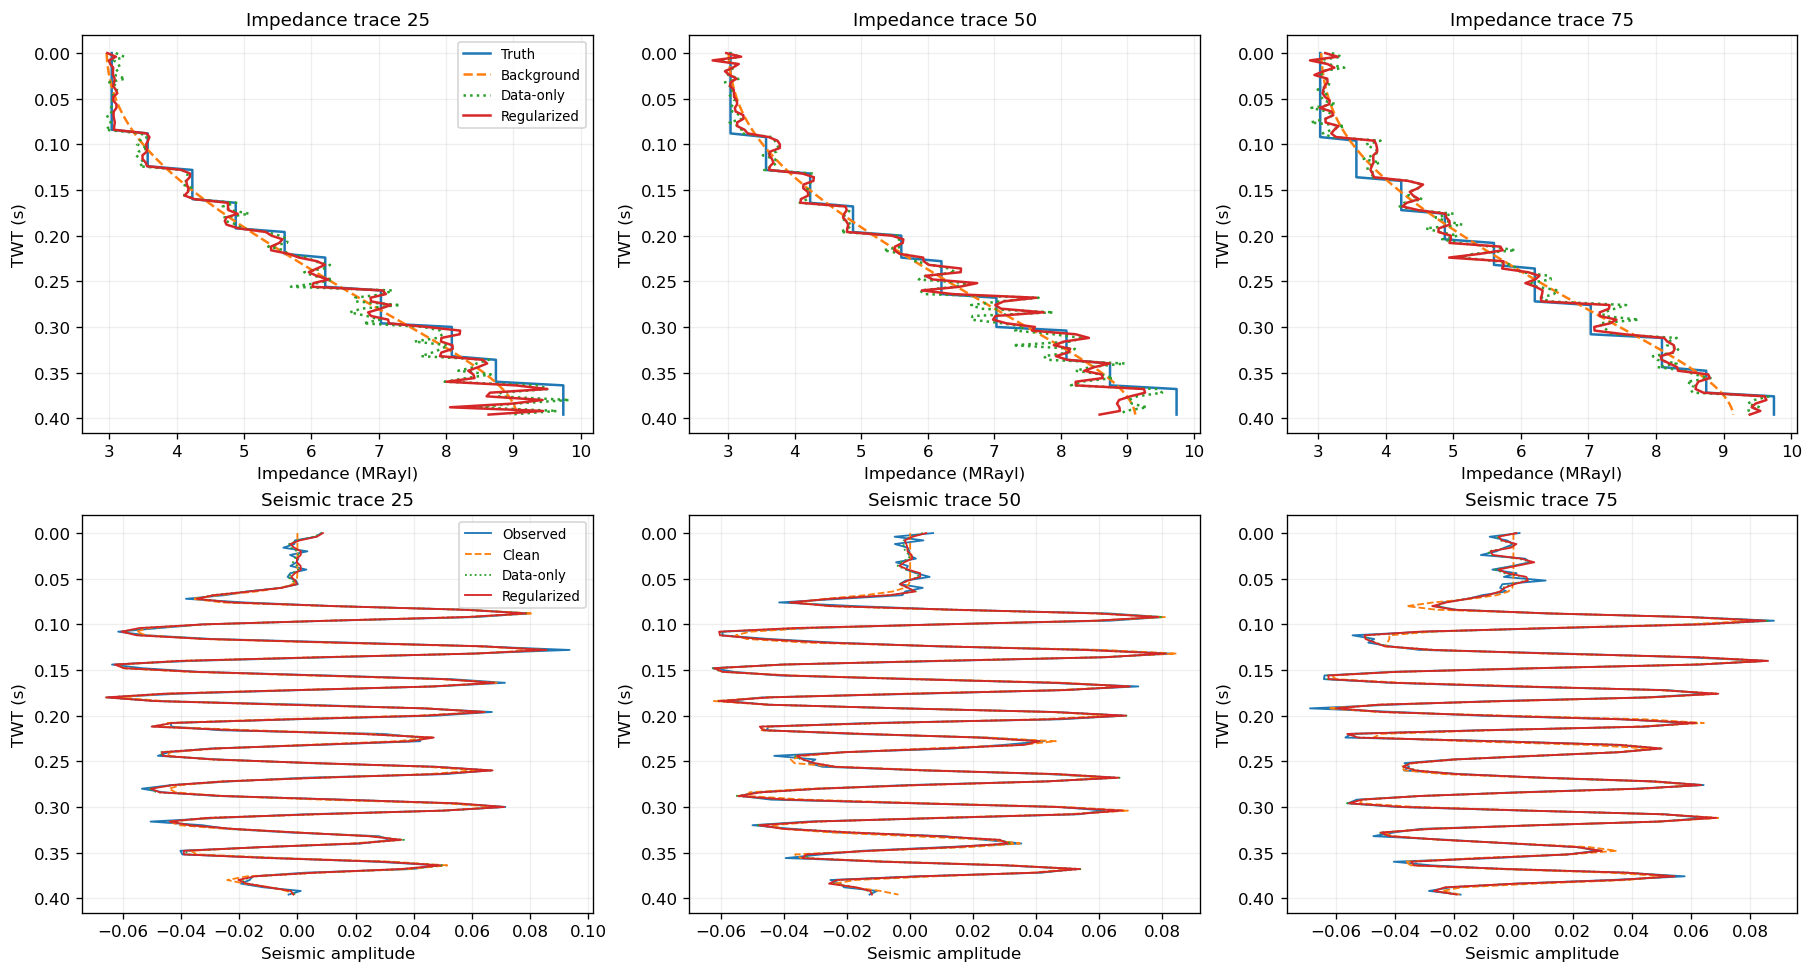

In [8]:
with torch.no_grad():
    Z_unreg=m_unreg.exp().cpu().numpy();Z_reg=m_reg.exp().cpu().numpy()
    d_unreg=torch_forward(m_unreg,w).cpu().numpy();d_reg=torch_forward(m_reg,w).cpu().numpy()
Z_bg=np.exp(mb)
fig,axs=plt.subplots(2,3,figsize=(15,8),constrained_layout=True)
models=[Z_true/1e6,Z_bg/1e6,Z_unreg/1e6,Z_reg/1e6,(Z_unreg-Z_true)/1e6,(Z_reg-Z_true)/1e6]
titles=['True impedance','Low-frequency background','Data-only AD inversion','Regularized AD + L-BFGS','Data-only error','Regularized error']
vmin=np.percentile(Z_true/1e6,1);vmax=np.percentile(Z_true/1e6,99)
errmax=np.percentile(np.abs(np.stack(models[-2:])),99)
for i,(a,A,title) in enumerate(zip(axs.flat,models,titles)):
    im=a.imshow(A,extent=[x[0],x[-1],t[-1],t[0]],aspect='auto',cmap='RdBu_r' if i>=4 else 'turbo',vmin=-errmax if i>=4 else vmin,vmax=errmax if i>=4 else vmax)
    a.set(title=title,xlabel='Distance (km)',ylabel='TWT (s)');fig.colorbar(im,ax=a,shrink=.85,label='MRayl')
fig.savefig(OUT/'06_impedance_comparison.png');plt.show()
fig,axs=plt.subplots(2,3,figsize=(15,8),constrained_layout=True)
seis=[clean,observed,d_unreg,d_reg,observed-d_unreg,observed-d_reg]
labels=['Clean seismic','Noisy observed seismic','Data-only predicted','Regularized predicted','Data-only residual','Regularized residual']
lim=np.percentile(abs(observed),99)
for a,A,title in zip(axs.flat,seis,labels):
    im=a.imshow(A,extent=[x[0],x[-1],t[-1],t[0]],aspect='auto',cmap='seismic',vmin=-lim,vmax=lim)
    a.set(title=title,xlabel='Distance (km)',ylabel='TWT (s)');fig.colorbar(im,ax=a,shrink=.85)
fig.savefig(OUT/'07_seismic_comparison.png');plt.show()
trace_ids=sorted(set([NX//4,NX//2,3*NX//4]))
fig,axs=plt.subplots(2,len(trace_ids),figsize=(15,8),constrained_layout=True)
for j,k in enumerate(trace_ids):
    a=axs[0,j]
    for A,label,ls in [(Z_true,'Truth','-'),(Z_bg,'Background','--'),(Z_unreg,'Data-only',':'),(Z_reg,'Regularized','-')]:a.plot(A[:,k]/1e6,t,label=label,ls=ls,lw=1.5)
    a.invert_yaxis();a.set(xlabel='Impedance (MRayl)',ylabel='TWT (s)',title=f'Impedance trace {k}');a.grid(alpha=.2)
    a=axs[1,j]
    for A,label,ls in [(observed,'Observed','-'),(clean,'Clean','--'),(d_unreg,'Data-only',':'),(d_reg,'Regularized','-')]:a.plot(A[:,k],t,label=label,ls=ls,lw=1.1)
    a.invert_yaxis();a.set(xlabel='Seismic amplitude',ylabel='TWT (s)',title=f'Seismic trace {k}');a.grid(alpha=.2)
axs[0,0].legend(fontsize=8);axs[1,0].legend(fontsize=8)
fig.savefig(OUT/'08_trace_comparisons.png');plt.show()

## 8. Quantitative benchmarking

Report impedance RMSE, relative RMSE, MAE, Pearson correlation, and seismic normalized RMS misfit. A lower seismic misfit **does not necessarily mean** better impedance recovery because noise and missing low frequencies create ambiguity.

,RMSE_MRayl,MAE_MRayl,RRMSE_percent,Correlation,Seismic_NRMSE
Method,,,,,
Background,0.2890,0.2137,4.8233,0.9932,NaN
Data-only AD,0.2869,0.2061,4.7898,0.9925,0.0816
Regularized AD,0.2722,0.1905,4.5440,0.9936,0.0845


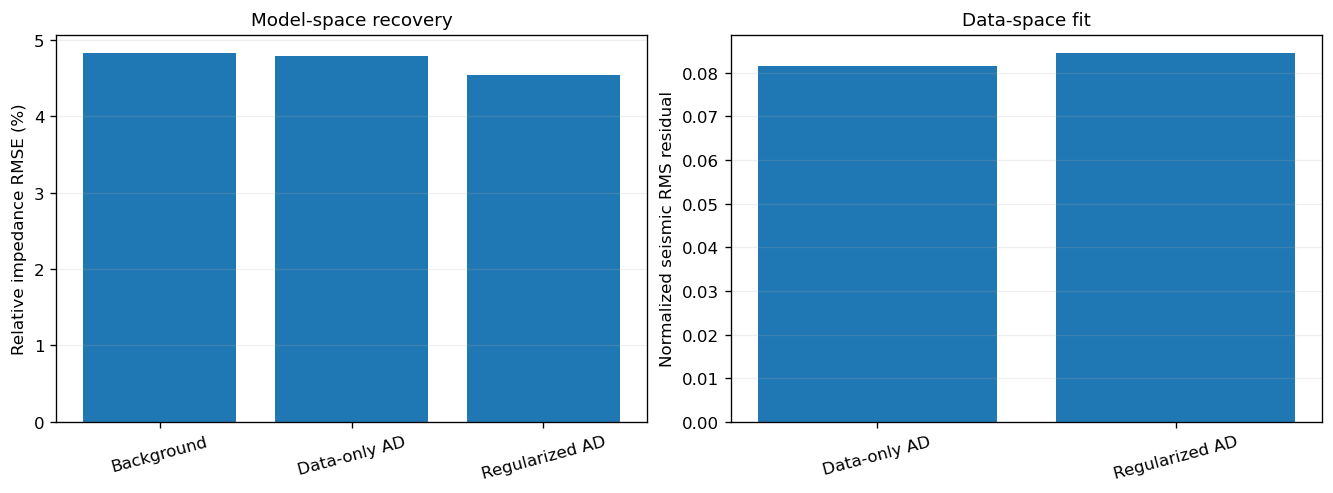

In [9]:
def metrics(z,pred):
    e=pred-z
    return dict(RMSE_MRayl=np.sqrt(np.mean(e**2))/1e6,MAE_MRayl=np.mean(abs(e))/1e6,
                RRMSE_percent=100*np.linalg.norm(e)/np.linalg.norm(z),
                Correlation=np.corrcoef(z.ravel(),pred.ravel())[0,1])
def seismic_nrmse(pred,target=observed):return np.linalg.norm(pred-target)/np.linalg.norm(target)
rows=[]
for name,z,d in [('Background',Z_bg,None),('Data-only AD',Z_unreg,d_unreg),('Regularized AD',Z_reg,d_reg)]:
    row={'Method':name,**metrics(Z_true,z),'Seismic_NRMSE':np.nan if d is None else seismic_nrmse(d)}
    rows.append(row)
try:
    import pandas as pd
    from IPython.display import display
    df=pd.DataFrame(rows).set_index('Method');display(df.round(4));df.to_csv(OUT/'metrics.csv')
except ImportError:
    for row in rows:print(row)
fig,axs=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
axs[0].bar([r['Method'] for r in rows],[r['RRMSE_percent'] for r in rows]);axs[0].set(ylabel='Relative impedance RMSE (%)',title='Model-space recovery')
axs[1].bar(['Data-only AD','Regularized AD'],[seismic_nrmse(d_unreg),seismic_nrmse(d_reg)]);axs[1].set(ylabel='Normalized seismic RMS residual',title='Data-space fit')
for a in axs:a.tick_params(axis='x',rotation=15);a.grid(axis='y',alpha=.2)
fig.savefig(OUT/'09_metrics.png');plt.show()

## 9. Sensitivity to the low-frequency background

A key lesson is that seismic data cannot uniquely supply the absolute low-frequency impedance. Compare the result to the background and visualize the vertical mean profiles. This is a diagnostic of background dependence, **not** a formal posterior uncertainty estimate.

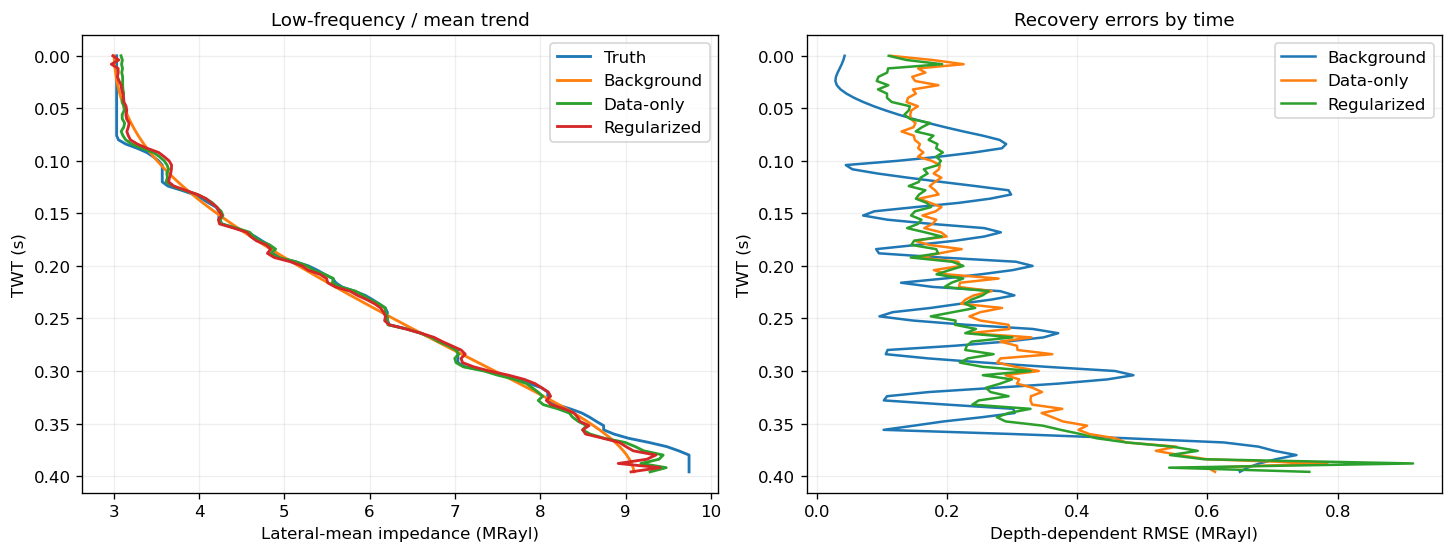

In [10]:
fig,axs=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
for A,label in [(Z_true,'Truth'),(Z_bg,'Background'),(Z_unreg,'Data-only'),(Z_reg,'Regularized')]:
    axs[0].plot(A.mean(axis=1)/1e6,t,label=label,lw=1.7)
axs[0].invert_yaxis();axs[0].set(xlabel='Lateral-mean impedance (MRayl)',ylabel='TWT (s)',title='Low-frequency / mean trend');axs[0].legend();axs[0].grid(alpha=.2)
for A,label in [(Z_bg-Z_true,'Background'),(Z_unreg-Z_true,'Data-only'),(Z_reg-Z_true,'Regularized')]:
    axs[1].plot(np.sqrt(np.mean(A**2,axis=1))/1e6,t,label=label)
axs[1].invert_yaxis();axs[1].set(xlabel='Depth-dependent RMSE (MRayl)',ylabel='TWT (s)',title='Recovery errors by time');axs[1].legend();axs[1].grid(alpha=.2)
fig.savefig(OUT/'10_depth_diagnostics.png');plt.show()

## 10. Export reproducible benchmark artifacts

The output includes numerical arrays, metrics and publication-style figures. Re-run with a different `MODE`, `INDEX`, SNR, wavelet frequency or background model to study robustness. For a serious benchmark, use multiple independent models, independently sourced backgrounds, blind hyperparameter selection, realistic wavelets, and uncertainty quantification.

In [11]:
np.savez_compressed(OUT/'poststack_inversion.npz',velocity_mps=vp,density_kgm3=rho,
    impedance_true=Z_true,impedance_background=Z_bg,impedance_data_only=Z_unreg,impedance_regularized=Z_reg,
    reflectivity_true=R_true,wavelet=w_np,clean_seismic=clean,observed_seismic=observed,
    predicted_data_only=d_unreg,predicted_regularized=d_reg,
    history_data_only=h_unreg,history_regularized=h_reg,dt=DT,dx=DX,snr_db=SNR_DB,source=source)
print('Saved:',OUT/'poststack_inversion.npz')
print('Figures:',len(list(OUT.glob('*.png'))),'| source:',source)
print('Regularized RRMSE:',metrics(Z_true,Z_reg)['RRMSE_percent'],'%')

Saved: geofwi_poststack_results/poststack_inversion.npz
Figures: 10 | source: GeoFWI 10-layer fold, local index 0, global index 43425
Regularized RRMSE: 4.5440483 %


## Discussion and research extensions

**What is actually inverted?** Log acoustic impedance $m=\log(\rho V_p)$, from which reflectivity and the post-stack synthetic trace are differentiated. The optimizer does not directly recover $V_p$ or density independently.

**Why AD?** PyTorch computes the exact computational gradient of the discretized nonlinear reflectivity-plus-convolution model. The gradient check confirms the implementation. AD is an optimization mechanism, not by itself a claim of state-of-the-art inversion accuracy.

**Why a low-frequency model?** A zero-mean band-limited wavelet removes the DC component and makes broad impedance trends poorly identifiable. The smooth background and its quality materially affect recovered absolute impedance.

**What could make this research-grade?** Add realistic time-depth mapping and well ties; estimate wavelet jointly; nonstationary and angle-dependent reflectivity; uncertainty via ensembles or Bayesian inference; independent GeoFWI train/test subsets; fault-aware directional TV; diffusion or learned geological priors trained without test leakage; multi-SNR blind validation. Compare with sparse-spike inversion, model-based deterministic inversion, and classical linearized log-impedance inversion. This notebook is a strong *educational baseline*, not evidence that it outperforms these methods.

**References:** Li et al. (2026), *GeoFWI: A Large Velocity Model Data Set for Benchmarking Full Waveform Inversion Using Deep Learning*, JGR: Machine Learning and Computation, https://doi.org/10.1029/2025JH001037; [GeoFWI GitHub](https://github.com/aaspip/geofwi).